# EDA - French Electricity Demand Forecasting

Exploratory Data Analysis for day-ahead electricity demand prediction.

**Objectives:**
1. Load and understand national and regional data
2. Verify if national load = sum of regional loads
3. Identify temporal patterns (hourly, daily, seasonal)
4. Quantify the RTE baseline performance (our benchmark)
5. Explore temperature effects and data quality issues

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

PROJECT_ROOT = Path('../')
DATA_DIR = PROJECT_ROOT / 'data'

print(f'Data directory: {DATA_DIR.resolve()}')

Data directory: /Users/hayterjulius/Library/CloudStorage/OneDrive-TheBostonConsultingGroup,Inc/Desktop/perso/time_series_m2/data


## 1. Load national data

In [2]:
df = pd.read_csv(DATA_DIR / 'france_electricity_hourly.csv')
df['datetime_utc'] = pd.to_datetime(df['datetime_utc'])
df = df.sort_values('datetime_utc').reset_index(drop=True)

print(f'Shape: {df.shape}')
print(f'Columns: {df.columns.tolist()}')
print(f"Range: {df['datetime_utc'].min()} -> {df['datetime_utc'].max()}")
print(f"Duration: {(df['datetime_utc'].max() - df['datetime_utc'].min()).days} days")
df.head()

Shape: (65710, 4)
Columns: ['datetime_utc', 'load_mw', 'rte_forecast_d1_mw', 'temperature_c']
Range: 2019-01-01 00:00:00+00:00 -> 2026-06-30 21:00:00+00:00
Duration: 2737 days


,datetime_utc,load_mw,rte_forecast_d1_mw,temperature_c
0,2019-01-01 00:00:00+00:00,60826.0,60838.0,5.85
1,2019-01-01 01:00:00+00:00,59786.0,59500.0,6.35
2,2019-01-01 02:00:00+00:00,56622.0,56012.0,5.91
3,2019-01-01 03:00:00+00:00,53920.0,53300.0,5.70
4,2019-01-01 04:00:00+00:00,52972.0,52188.0,5.72


In [3]:
print('Dtypes:')
print(df.dtypes)
print()
print('Missing values:')
print(df.isnull().sum())
print()
df.describe()

Dtypes:
datetime_utc          datetime64[ns, UTC]
load_mw                           float64
rte_forecast_d1_mw                float64
temperature_c                     float64
dtype: object

Missing values:
datetime_utc          0
load_mw               7
rte_forecast_d1_mw    7
temperature_c         0
dtype: int64



,load_mw,rte_forecast_d1_mw,temperature_c
count,65703.000000,65703.000000,65710.000000
mean,51498.463921,50831.565104,13.071639
std,11018.913253,11048.172035,7.022981
min,29364.000000,27712.000000,-5.090000
25%,43321.500000,42600.000000,7.920000
50%,49768.000000,48962.000000,12.500000
75%,58747.500000,58062.000000,17.980000
max,90210.000000,89975.000000,38.520000


## 2. Load regional data

The regional file is in **long format**: one row per (region, hour).

In [4]:
df_regional = pd.read_csv(DATA_DIR / 'france_regional_electricity_hourly.csv')
df_regional['datetime_utc'] = pd.to_datetime(df_regional['datetime_utc'])
df_regional['load_mw'] = pd.to_numeric(df_regional['load_mw'], errors='coerce')
df_regional['temperature_c'] = pd.to_numeric(df_regional['temperature_c'], errors='coerce')
df_regional = df_regional.sort_values(['datetime_utc', 'region']).reset_index(drop=True)

print(f'Shape: {df_regional.shape}')
print(f'Columns: {df_regional.columns.tolist()}')
print()
print('Missing values:')
print(df_regional.isnull().sum())
df_regional.head()

Shape: (367752, 4)
Columns: ['region', 'datetime_utc', 'load_mw', 'temperature_c']

Missing values:
region            0
datetime_utc      0
load_mw          36
temperature_c     0
dtype: int64


,region,datetime_utc,load_mw,temperature_c
0,Auvergne-Rhône-Alpes,2023-01-01 00:00:00+00:00,6028.0,13.3
1,Bourgogne-Franche-Comté,2023-01-01 00:00:00+00:00,1803.0,10.3
2,Bretagne,2023-01-01 00:00:00+00:00,2486.0,13.2
3,Centre-Val de Loire,2023-01-01 00:00:00+00:00,1969.0,14.3
4,Grand Est,2023-01-01 00:00:00+00:00,3732.0,12.0


In [5]:
regions = sorted(df_regional['region'].unique())
print(f'Number of regions: {len(regions)}')
print(regions)
print()
print('Mean load per region (MW):')
print(df_regional.groupby('region')['load_mw'].mean().sort_values(ascending=False).round(0))

# CRITICAL: the two files do not cover the same period
print()
print('--- Coverage comparison ---')
print(f"National: {df['datetime_utc'].min().date()} -> {df['datetime_utc'].max().date()} "
      f"({len(df)} hours)")
print(f"Regional: {df_regional['datetime_utc'].min().date()} -> "
      f"{df_regional['datetime_utc'].max().date()} "
      f"({df_regional['datetime_utc'].nunique()} hours)")
overlap = df_regional['datetime_utc'].nunique() / len(df) * 100
print(f'Regional covers only {overlap:.0f}% of the national history.')


Number of regions: 12
['Auvergne-Rhône-Alpes', 'Bourgogne-Franche-Comté', 'Bretagne', 'Centre-Val de Loire', 'Grand Est', 'Hauts-de-France', 'Normandie', 'Nouvelle-Aquitaine', 'Occitanie', 'Pays de la Loire', "Provence-Alpes-Côte d'Azur", 'Île-de-France']

Mean load per region (MW):
region
Île-de-France                 7426.0
Auvergne-Rhône-Alpes          7111.0
Hauts-de-France               5331.0
Grand Est                     4771.0
Nouvelle-Aquitaine            4706.0
Provence-Alpes-Côte d'Azur    4406.0
Occitanie                     4153.0
Normandie                     2963.0
Pays de la Loire              2900.0
Bretagne                      2482.0
Bourgogne-Franche-Comté       2242.0
Centre-Val de Loire           2026.0
Name: load_mw, dtype: float64

--- Coverage comparison ---
National: 2019-01-01 -> 2026-06-30 (65710 hours)
Regional: 2023-01-01 -> 2026-06-30 (30646 hours)
Regional covers only 47% of the national history.


## 3. National vs regional aggregation

Does the sum of the regions reconstruct the national series? If yes, the regional file gives us
a finer-grained view (regional temperatures, regional mix) we could exploit later.

In [6]:
# min_count=1: without it, an hour where every region is NaN sums to 0 MW, not NaN
regional_total = (
    df_regional.groupby('datetime_utc')['load_mw']
    .sum(min_count=1)
    .rename('total_regional_load')
    .reset_index()
)
print(f"Hours where all regions are NaN: {regional_total['total_regional_load'].isna().sum()}")

comparison = df[['datetime_utc', 'load_mw']].merge(regional_total, on='datetime_utc', how='inner')
comparison = comparison.dropna(subset=['load_mw', 'total_regional_load'])
comparison['difference'] = comparison['load_mw'] - comparison['total_regional_load']
comparison['ratio'] = comparison['load_mw'] / comparison['total_regional_load']

print(f'Matched hours: {len(comparison)}')
print(f"Mean difference : {comparison['difference'].mean():.1f} MW")
print(f"Std difference  : {comparison['difference'].std():.1f} MW")
print(f"Max |difference|: {comparison['difference'].abs().max():.1f} MW")
print(f"Mean ratio      : {comparison['ratio'].mean():.4f}")
print(f"Correlation     : {comparison['load_mw'].corr(comparison['total_regional_load']):.5f}")

Hours where all regions are NaN: 3
Matched hours: 30643
Mean difference : -0.0 MW
Std difference  : 9.4 MW
Max |difference|: 1620.0 MW
Mean ratio      : 1.0000
Correlation     : 1.00000


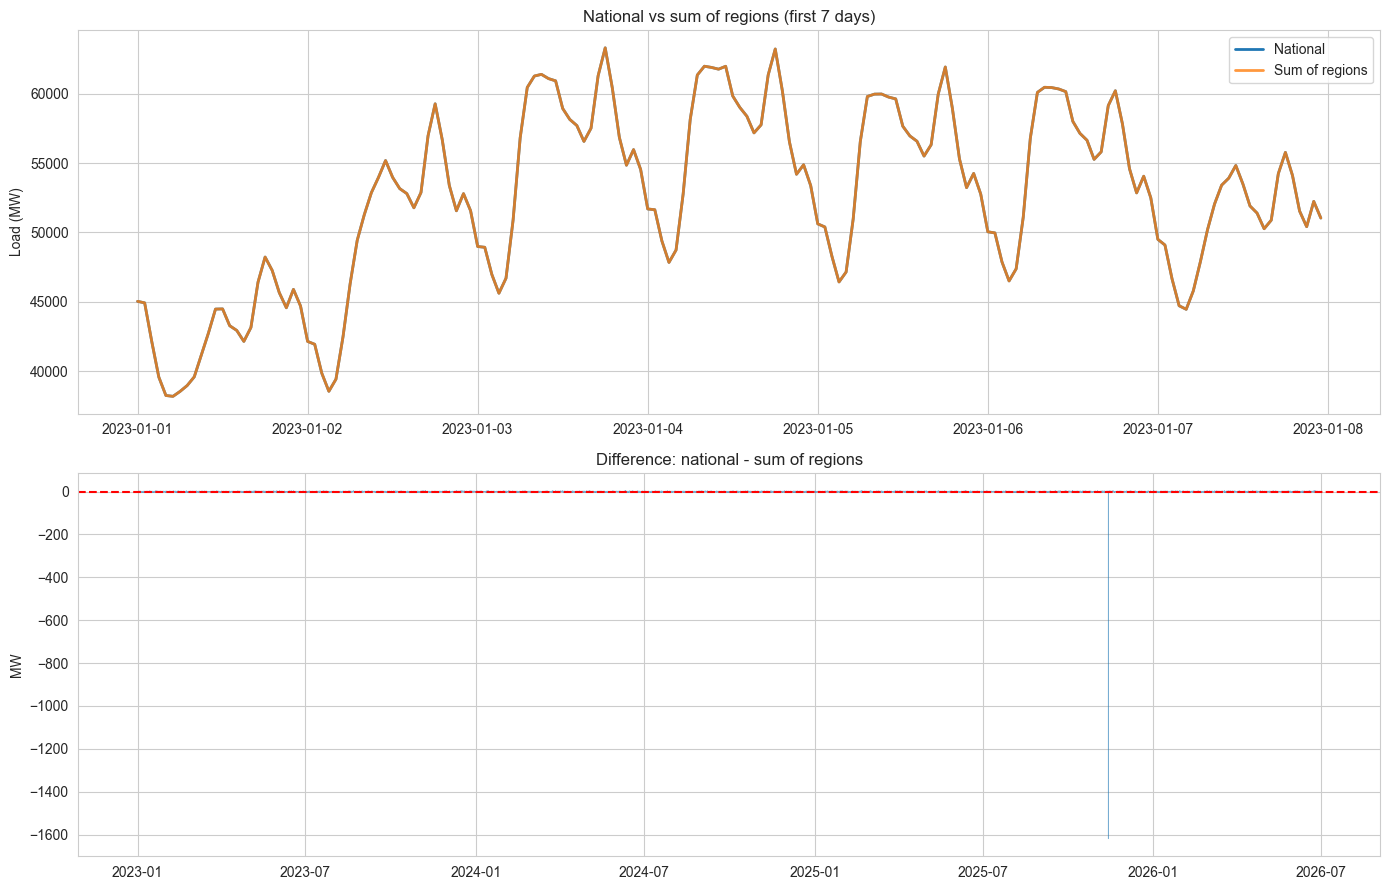

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

mask = comparison['datetime_utc'] < comparison['datetime_utc'].min() + pd.Timedelta(days=7)
axes[0].plot(comparison.loc[mask, 'datetime_utc'], comparison.loc[mask, 'load_mw'],
             label='National', linewidth=2)
axes[0].plot(comparison.loc[mask, 'datetime_utc'], comparison.loc[mask, 'total_regional_load'],
             label='Sum of regions', linewidth=2, alpha=0.8)
axes[0].set_title('National vs sum of regions (first 7 days)')
axes[0].set_ylabel('Load (MW)')
axes[0].legend()

axes[1].plot(comparison['datetime_utc'], comparison['difference'], linewidth=0.4, alpha=0.6)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_title('Difference: national - sum of regions')
axes[1].set_ylabel('MW')

plt.tight_layout()
plt.show()

## 4. Data quality

Before modelling: missing hours, duplicates, DST gaps, frozen values and extreme observations.

In [8]:
print('--- Missing values ---')
for col in ['load_mw', 'rte_forecast_d1_mw', 'temperature_c']:
    n = df[col].isnull().sum()
    print(f'{col:22s}: {n:5d} ({n / len(df) * 100:.3f}%)')

print()
print(f"Duplicated timestamps: {df['datetime_utc'].duplicated().sum()}")

expected = pd.date_range(df['datetime_utc'].min(), df['datetime_utc'].max(), freq='h', tz='UTC')
missing_hours = expected.difference(df['datetime_utc'])
print(f'Expected hours: {len(expected)} | present: {len(df)} | missing: {len(missing_hours)}')
if len(missing_hours) > 0:
    print('First missing timestamps:')
    print(missing_hours[:10])

--- Missing values ---
load_mw               :     7 (0.011%)
rte_forecast_d1_mw    :     7 (0.011%)
temperature_c         :     0 (0.000%)

Duplicated timestamps: 0
Expected hours: 65710 | present: 65710 | missing: 0


In [9]:
# Where are the NaNs located in time? (matters for lag features)
nan_rows = df[df['load_mw'].isnull()]
print(f'Rows with missing load: {len(nan_rows)}')
print(nan_rows[['datetime_utc', 'load_mw', 'rte_forecast_d1_mw', 'temperature_c']])
print()
print('Dates concerned:')
print(nan_rows['datetime_utc'].dt.strftime('%Y-%m-%d (%A)').tolist())


Rows with missing load: 7
                   datetime_utc  load_mw  rte_forecast_d1_mw  temperature_c
7176  2019-10-27 00:00:00+00:00      NaN                 NaN          15.13
15912 2020-10-25 00:00:00+00:00      NaN                 NaN          13.64
24816 2021-10-31 00:00:00+00:00      NaN                 NaN          11.86
33552 2022-10-30 00:00:00+00:00      NaN                 NaN          14.97
42288 2023-10-29 00:00:00+00:00      NaN                 NaN          14.41
51024 2024-10-27 00:00:00+00:00      NaN                 NaN          12.97
59760 2025-10-26 00:00:00+00:00      NaN                 NaN           8.86

Dates concerned:
['2019-10-27 (Sunday)', '2020-10-25 (Sunday)', '2021-10-31 (Sunday)', '2022-10-30 (Sunday)', '2023-10-29 (Sunday)', '2024-10-27 (Sunday)', '2025-10-26 (Sunday)']


The hourly index is **complete** (cell above: 0 missing timestamps). The seven gaps are NaN
*values* inside rows that exist: `load_mw` and `rte_forecast_d1_mw` are both null while
`temperature_c` is present.

They all fall on the last Sunday of October at 00:00 UTC, i.e. the end of daylight saving time.
Since the series is indexed in UTC there is no discontinuity in the index itself; what is missing
is the RTE publication at the fall-back hour, when the local clock repeats 02:00-03:00.
Seven isolated hours over 7.5 years: safe to interpolate, but DST transition days deserve a flag
because the local daily profile is shifted on those days.

In [10]:
# Frozen sensor would hold the SAME value over consecutive hours -> measure run lengths
same_as_previous = df['load_mw'].eq(df['load_mw'].shift())
run_id = (~same_as_previous).cumsum()
run_lengths = df.groupby(run_id)['load_mw'].size()
print(f'Longest run of identical consecutive values: {run_lengths.max()} hours')
print(f'Runs of 3+ identical hours: {(run_lengths >= 3).sum()}')

# Extreme hour-to-hour jumps
df['load_diff'] = df['load_mw'].diff()
big_jumps = df[df['load_diff'].abs() > 8000]
print(f'Hour-to-hour jumps > 8000 MW: {len(big_jumps)}')
if len(big_jumps) > 0:
    print(big_jumps[['datetime_utc', 'load_mw', 'load_diff']].head(10))

# IQR outliers on the raw level (expected: winter peaks, not errors)
q1, q3 = df['load_mw'].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = df[(df['load_mw'] < q1 - 1.5 * iqr) | (df['load_mw'] > q3 + 1.5 * iqr)]
n_outliers = len(outliers)
outlier_months = outliers['datetime_utc'].dt.month.value_counts().sort_index()
print()
print(f'IQR outliers: {n_outliers} ({n_outliers / len(df) * 100:.2f}%)')
print('Months concerned:')
print(outlier_months)

Longest run of identical consecutive values: 2 hours
Runs of 3+ identical hours: 0
Hour-to-hour jumps > 8000 MW: 1
                  datetime_utc  load_mw  load_diff
1314 2019-02-24 18:00:00+00:00  58349.0     8101.0

IQR outliers: 343 (0.52%)
Months concerned:
datetime_utc
1     294
2      34
11      1
12     14
Name: count, dtype: int64


## 5. Temporal patterns

In [11]:
# Consumption follows the Paris clock, not UTC. Deriving hour-of-day from UTC would smear
# two different local hours together on either side of each DST switch.
df['datetime_local'] = df['datetime_utc'].dt.tz_convert('Europe/Paris')
df['hour'] = df['datetime_local'].dt.hour
df['day_of_week'] = df['datetime_local'].dt.dayofweek  # 0 = Monday
df['month'] = df['datetime_local'].dt.month
df['year'] = df['datetime_local'].dt.year
df['date'] = df['datetime_local'].dt.date

DAY_NAMES = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
MONTH_NAMES = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
MONTH_LABELS = dict(enumerate(MONTH_NAMES, start=1))
DAY_LABELS = dict(enumerate(DAY_NAMES))

hourly_stats = df.groupby('hour')['load_mw'].agg(['mean', 'std', 'min', 'max'])
peak_hour = int(hourly_stats['mean'].idxmax())
trough_hour = int(hourly_stats['mean'].idxmin())

print('Load by hour of day (Europe/Paris):')
print(hourly_stats.round(0))
print()
print(f"Peak hour  : {peak_hour}h local ({hourly_stats['mean'].max():.0f} MW)")
print(f"Trough hour: {trough_hour}h local ({hourly_stats['mean'].min():.0f} MW)")
print(f"Peak-trough spread: {hourly_stats['mean'].max() - hourly_stats['mean'].min():.0f} MW")

Load by hour of day (Europe/Paris):
         mean      std      min      max
hour                                    
0     51037.0   9321.0  37448.0  79932.0
1     47730.0   9544.0  34362.0  77602.0
2     46743.0   9787.0  33449.0  77018.0
3     44591.0   9761.0  31448.0  74980.0
4     43258.0   9694.0  30392.0  73592.0
5     43773.0   9972.0  30051.0  74296.0
6     46336.0  10887.0  29431.0  77682.0
7     49935.0  12190.0  29364.0  82864.0
8     52722.0  12539.0  30792.0  87372.0
9     54587.0  11963.0  33210.0  89498.0
10    55476.0  11207.0  35792.0  90210.0
11    55917.0  10554.0  38168.0  89254.0
12    56863.0   9976.0  40137.0  88387.0
13    56516.0   9488.0  39857.0  86964.0
14    54654.0   9323.0  37418.0  84344.0
15    53163.0   9134.0  35802.0  82710.0
16    51810.0   9200.0  34378.0  81316.0
17    51485.0   9736.0  33856.0  81928.0
18    53230.0  10914.0  34624.0  86347.0
19    55609.0  11434.0  36620.0  89416.0
20    54532.0  10672.0  36990.0  87174.0
21    52212.0   9752.

In [12]:
dow_stats = df.groupby('day_of_week')['load_mw'].agg(['mean', 'std']).rename(index=DAY_LABELS)
print('Load by day of week:')
print(dow_stats.round(0))

weekday_mean = df.loc[df['day_of_week'] < 5, 'load_mw'].mean()
weekend_mean = df.loc[df['day_of_week'] >= 5, 'load_mw'].mean()
print()
print(f'Weekday mean: {weekday_mean:.0f} MW')
print(f'Weekend mean: {weekend_mean:.0f} MW')
print(f'Gap: {weekday_mean - weekend_mean:.0f} MW '
      f'({(weekday_mean - weekend_mean) / weekend_mean * 100:.1f}%)')

Load by day of week:
                mean      std
day_of_week                  
Mon          52257.0  11463.0
Tue          53458.0  10995.0
Wed          53434.0  10789.0
Thu          53294.0  10717.0
Fri          52791.0  10674.0
Sat          48531.0  10106.0
Sun          46716.0  10278.0

Weekday mean: 53047 MW
Weekend mean: 47624 MW
Gap: 5423 MW (11.4%)


In [13]:
monthly_stats = (df.groupby('month')['load_mw']
                 .agg(['mean', 'std', 'min', 'max'])
                 .rename(index=MONTH_LABELS))
print('Load by month:')
print(monthly_stats.round(0))

winter_mean = df.loc[df['month'].isin([12, 1, 2]), 'load_mw'].mean()
summer_mean = df.loc[df['month'].isin([6, 7, 8]), 'load_mw'].mean()
print()
print(f'Winter (DJF): {winter_mean:.0f} MW')
print(f'Summer (JJA): {summer_mean:.0f} MW')
print(f'Ratio: {winter_mean / summer_mean:.2f}x')

# Partial years cannot be compared to full ones: load is strongly seasonal, so a Jan-Jun year
# looks artificially high. Flag them instead of reading a fake trend.
yearly_load = df.groupby('year').agg(mean_load=('load_mw', 'mean'), hours=('load_mw', 'size'))
yearly_load['complete'] = yearly_load['hours'] >= 8000
COMPLETE_YEARS = yearly_load.index[yearly_load['complete']].tolist()
print()
print('Yearly mean load (trend check):')
print(yearly_load.round(0))
print(f'Complete years: {COMPLETE_YEARS}')
print('Partial years are excluded from any trend statement.')

Load by month:
          mean     std      min      max
month                                   
Jan    67663.0  8692.0  38179.0  90210.0
Feb    62022.0  7411.0  44181.0  86321.0
Mar    55709.0  6777.0  39260.0  78114.0
Apr    48503.0  6955.0  31028.0  73761.0
May    43703.0  5621.0  29364.0  62057.0
Jun    43848.0  5922.0  29916.0  60234.0
Jul    44249.0  5884.0  30606.0  59557.0
Aug    41756.0  5324.0  30051.0  54852.0
Sep    43873.0  5646.0  30972.0  57463.0
Oct    47040.0  6308.0  30864.0  64174.0
Nov    56154.0  8555.0  33265.0  82928.0
Dec    62270.0  8013.0  39940.0  84230.0

Winter (DJF): 64124 MW
Summer (JJA): 43304 MW
Ratio: 1.48x

Yearly mean load (trend check):
      mean_load  hours  complete
year                            
2019    53707.0   8759      True
2020    50841.0   8784      True
2021    53493.0   8760      True
2022    51388.0   8760      True
2023    49723.0   8760      True
2024    50101.0   8784      True
2025    50672.0   8760      True
2026    52648.0   434

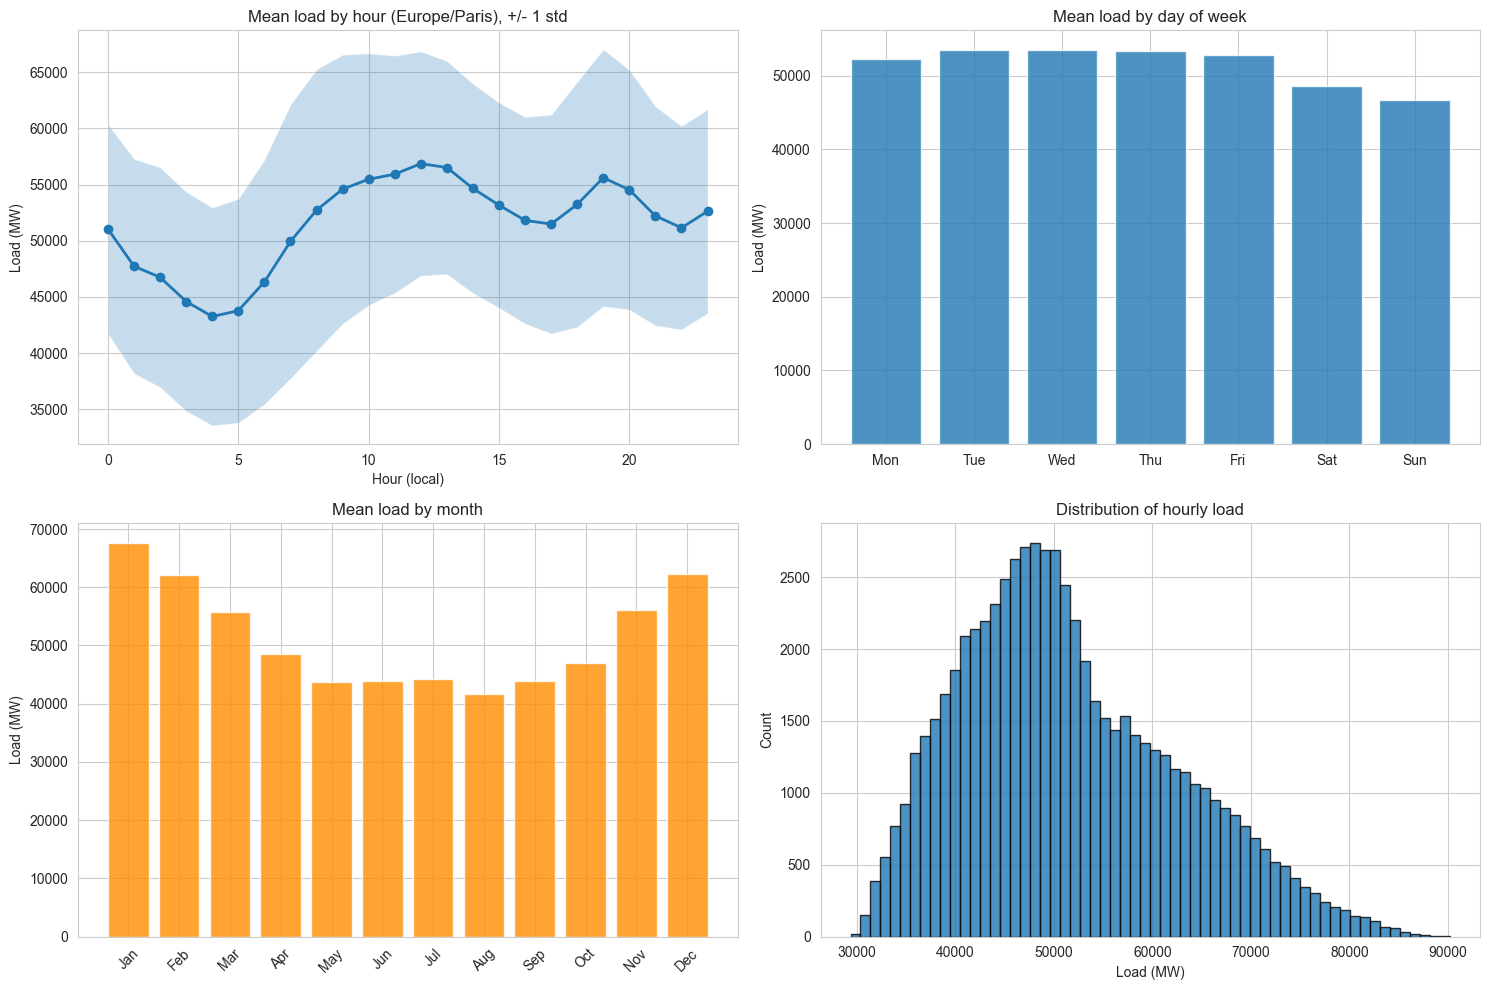

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes[0, 0].plot(hourly_stats.index, hourly_stats['mean'], marker='o', linewidth=2)
axes[0, 0].fill_between(hourly_stats.index,
                        hourly_stats['mean'] - hourly_stats['std'],
                        hourly_stats['mean'] + hourly_stats['std'], alpha=0.25)
axes[0, 0].set_title('Mean load by hour (Europe/Paris), +/- 1 std')
axes[0, 0].set_xlabel('Hour (local)')
axes[0, 0].set_ylabel('Load (MW)')

axes[0, 1].bar(range(7), dow_stats['mean'], alpha=0.8)
axes[0, 1].set_xticks(range(7))
axes[0, 1].set_xticklabels(DAY_NAMES)
axes[0, 1].set_title('Mean load by day of week')
axes[0, 1].set_ylabel('Load (MW)')

axes[1, 0].bar(range(12), monthly_stats['mean'], alpha=0.8, color='darkorange')
axes[1, 0].set_xticks(range(12))
axes[1, 0].set_xticklabels(MONTH_NAMES, rotation=45)
axes[1, 0].set_title('Mean load by month')
axes[1, 0].set_ylabel('Load (MW)')

axes[1, 1].hist(df['load_mw'].dropna(), bins=60, alpha=0.8, edgecolor='black')
axes[1, 1].set_title('Distribution of hourly load')
axes[1, 1].set_xlabel('Load (MW)')
axes[1, 1].set_ylabel('Count')

plt.tight_layout()
plt.show()

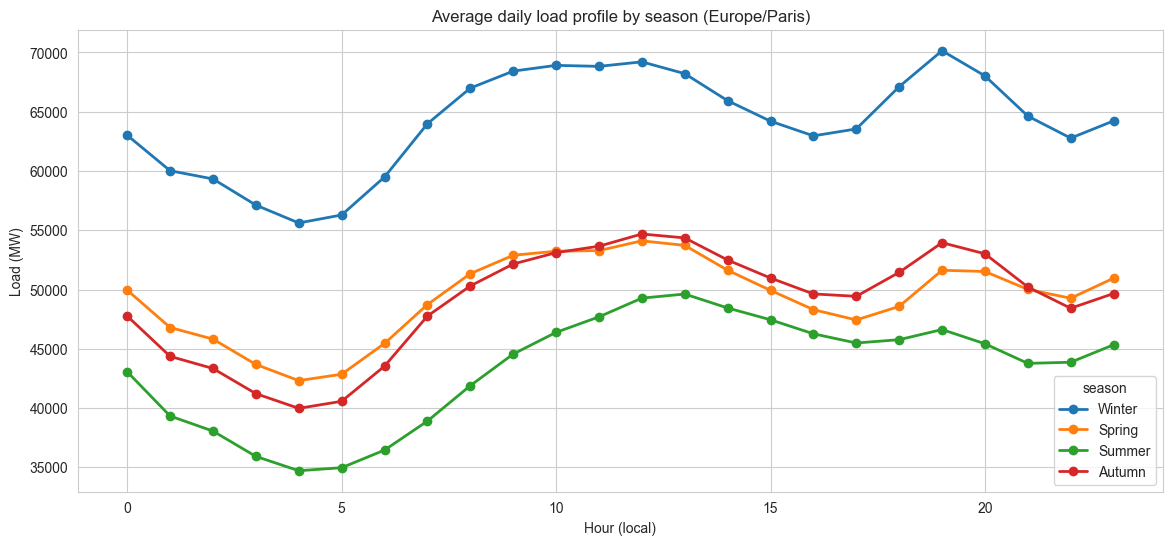

Peak hour per season (local time):
season
Winter    19
Spring    12
Summer    13
Autumn    12
dtype: int32

Intra-day amplitude (max - min) per season, MW:
season
Winter    14529.0
Spring    11791.0
Summer    14904.0
Autumn    14707.0
dtype: float64


In [15]:
# Daily profile per season: the shape itself changes, not only the level
season_map = {12: 'Winter', 1: 'Winter', 2: 'Winter',
              3: 'Spring', 4: 'Spring', 5: 'Spring',
              6: 'Summer', 7: 'Summer', 8: 'Summer',
              9: 'Autumn', 10: 'Autumn', 11: 'Autumn'}
df['season'] = df['month'].map(season_map)

profile = df.pivot_table(index='hour', columns='season', values='load_mw', aggfunc='mean')
profile = profile[['Winter', 'Spring', 'Summer', 'Autumn']]

profile.plot(figsize=(14, 6), marker='o', linewidth=2)
plt.title('Average daily load profile by season (Europe/Paris)')
plt.xlabel('Hour (local)')
plt.ylabel('Load (MW)')
plt.grid(True)
plt.show()

print('Peak hour per season (local time):')
print(profile.idxmax())
print()
print('Intra-day amplitude (max - min) per season, MW:')
print((profile.max() - profile.min()).round(0))

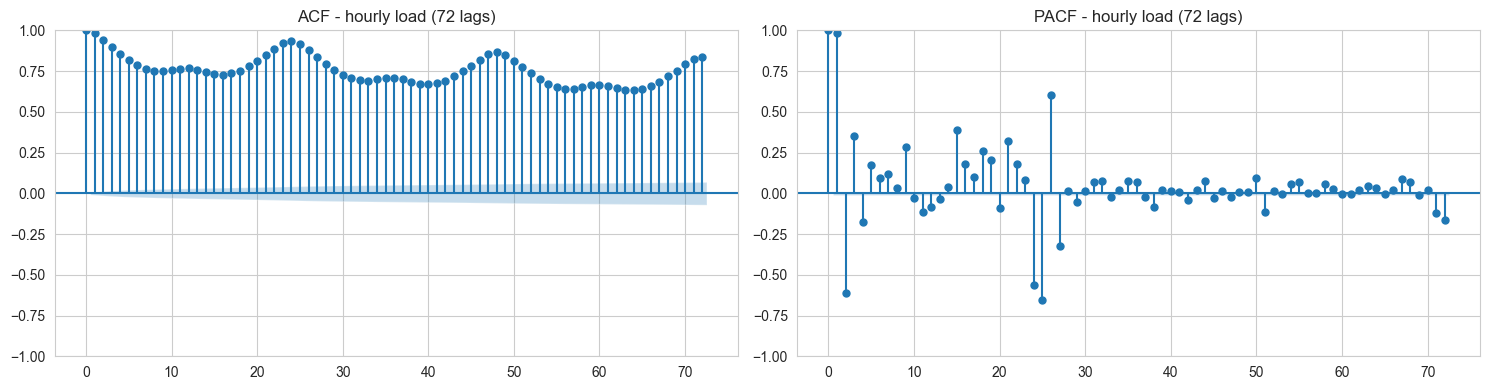

Autocorrelation at lag    1h: 0.982
Autocorrelation at lag    2h: 0.942
Autocorrelation at lag   24h: 0.937
Autocorrelation at lag   48h: 0.867
Autocorrelation at lag  168h: 0.893


In [16]:
# Autocorrelation: how much signal is in the recent past?
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

load_series = df['load_mw'].interpolate()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
plot_acf(load_series, lags=72, ax=axes[0])
axes[0].set_title('ACF - hourly load (72 lags)')
plot_pacf(load_series, lags=72, ax=axes[1], method='ywm')
axes[1].set_title('PACF - hourly load (72 lags)')
plt.tight_layout()
plt.show()

KEY_LAGS = [1, 2, 24, 48, 168]
autocorr = {lag: load_series.autocorr(lag) for lag in KEY_LAGS}
for lag, value in autocorr.items():
    print(f'Autocorrelation at lag {lag:4d}h: {value:.3f}')

## 6. Temperature effect

In [17]:
df_temp = df.dropna(subset=['load_mw', 'temperature_c']).copy()
temp_corr = df_temp['temperature_c'].corr(df_temp['load_mw'])

# Open-ended outer edges: a future cold snap below -10C must not silently vanish from the table
TEMP_BINS = [-np.inf, 0, 5, 10, 15, 20, 25, np.inf]

print(f'Correlation(temperature, load): {temp_corr:.3f}')
print(f"Observed temperature range: {df_temp['temperature_c'].min():.1f}C "
      f"to {df_temp['temperature_c'].max():.1f}C")
print()
print('Mean load by temperature bucket:')
df_temp['temp_bucket'] = pd.cut(df_temp['temperature_c'], bins=TEMP_BINS)
print(df_temp.groupby('temp_bucket', observed=False)['load_mw'].agg(['count', 'mean', 'max']).round(0))

cold = df_temp[df_temp['temperature_c'] < 0]
print()
print(f'Hours below 0C: {len(cold)} ({len(cold) / len(df_temp) * 100:.2f}%)')
print(f"Mean load below 0C: {cold['load_mw'].mean():.0f} MW "
      f"vs overall {df_temp['load_mw'].mean():.0f} MW")

Correlation(temperature, load): -0.605
Observed temperature range: -5.1C to 38.5C

Mean load by temperature bucket:
              count     mean      max
temp_bucket                          
(-inf, 0.0]    1016  71953.0  90210.0
(0.0, 5.0]     7271  65758.0  88106.0
(5.0, 10.0]   15738  57561.0  84979.0
(10.0, 15.0]  16544  48748.0  76685.0
(15.0, 20.0]  13815  43371.0  64133.0
(20.0, 25.0]   7824  45081.0  55855.0
(25.0, inf]    3495  48098.0  60234.0

Hours below 0C: 1010 (1.54%)
Mean load below 0C: 71989 MW vs overall 51498 MW


In [18]:
# Heating / cooling degree-days around a 15C comfort threshold
BASE_TEMP = 15.0
df_temp['hdd'] = (BASE_TEMP - df_temp['temperature_c']).clip(lower=0)
df_temp['cdd'] = (df_temp['temperature_c'] - BASE_TEMP).clip(lower=0)

print(f"Correlation(HDD, load): {df_temp['hdd'].corr(df_temp['load_mw']):.3f}")
print(f"Correlation(CDD, load): {df_temp['cdd'].corr(df_temp['load_mw']):.3f}")

# Thermal gradient: MW gained per degree lost, estimated on cold hours only
cold_mask = df_temp['temperature_c'] < BASE_TEMP
slope = np.polyfit(df_temp.loc[cold_mask, 'temperature_c'],
                   df_temp.loc[cold_mask, 'load_mw'], 1)[0]
print(f'Thermal gradient below {BASE_TEMP}C: {slope:.0f} MW per +1C '
      f'(i.e. {abs(slope):.0f} MW per -1C)')

Correlation(HDD, load): 0.716
Correlation(CDD, load): -0.292
Thermal gradient below 15.0C: -1797 MW per +1C (i.e. 1797 MW per -1C)


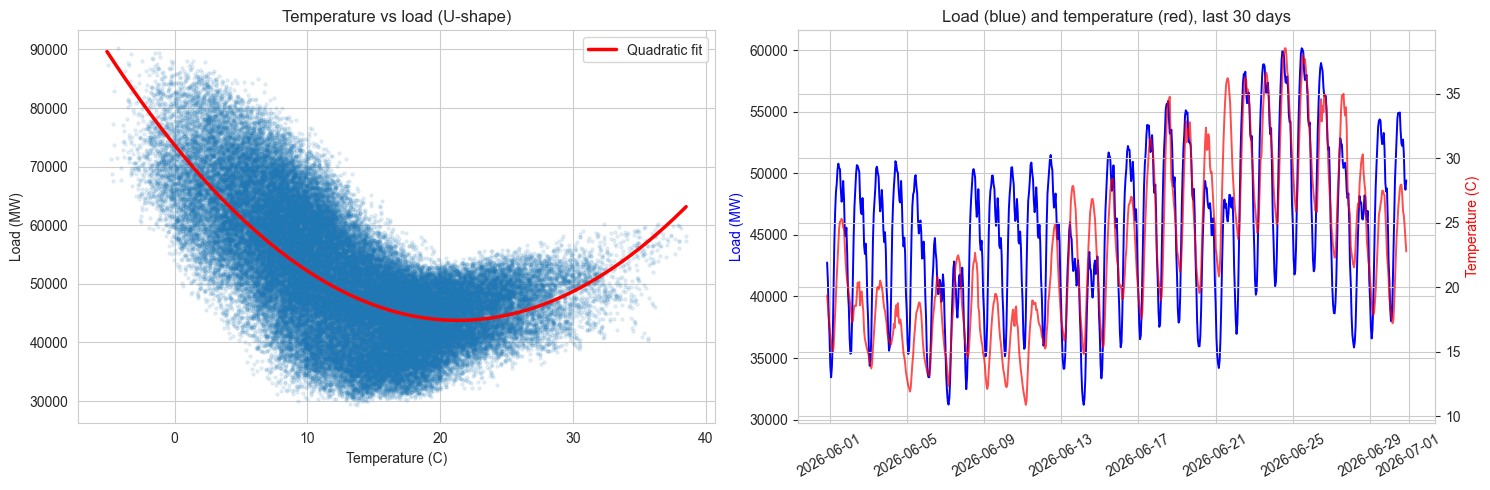

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(df_temp['temperature_c'], df_temp['load_mw'], alpha=0.1, s=5)
coeffs = np.polyfit(df_temp['temperature_c'], df_temp['load_mw'], 2)
grid = np.linspace(df_temp['temperature_c'].min(), df_temp['temperature_c'].max(), 200)
axes[0].plot(grid, np.poly1d(coeffs)(grid), 'r-', linewidth=2.5, label='Quadratic fit')
axes[0].set_title('Temperature vs load (U-shape)')
axes[0].set_xlabel('Temperature (C)')
axes[0].set_ylabel('Load (MW)')
axes[0].legend()

mask_30d = df['datetime_utc'] >= df['datetime_utc'].max() - pd.Timedelta(days=30)
ax = axes[1]
ax_t = ax.twinx()
ax.plot(df.loc[mask_30d, 'datetime_utc'], df.loc[mask_30d, 'load_mw'], 'b-', linewidth=1.4)
ax_t.plot(df.loc[mask_30d, 'datetime_utc'], df.loc[mask_30d, 'temperature_c'], 'r-',
          linewidth=1.4, alpha=0.7)
ax.set_title('Load (blue) and temperature (red), last 30 days')
ax.set_ylabel('Load (MW)', color='b')
ax_t.set_ylabel('Temperature (C)', color='r')
ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## 7. RTE baseline performance

This is the benchmark we must beat. We measure it the same way we will measure our own models.

In [20]:
df_rte = df.dropna(subset=['load_mw', 'rte_forecast_d1_mw']).copy()
df_rte['error'] = df_rte['load_mw'] - df_rte['rte_forecast_d1_mw']
df_rte['abs_error'] = df_rte['error'].abs()
df_rte['pct_error'] = df_rte['abs_error'] / df_rte['load_mw'] * 100

rte_mae = df_rte['abs_error'].mean()
rte_rmse = np.sqrt((df_rte['error'] ** 2).mean())
rte_mape = df_rte['pct_error'].mean()
rte_bias = df_rte['error'].mean()

print('RTE day-ahead forecast, full sample')
print(f'MAE  : {rte_mae:.1f} MW')
print(f'RMSE : {rte_rmse:.1f} MW')
print(f'MAPE : {rte_mape:.2f}%')
print(f'Bias : {rte_bias:+.1f} MW  (positive = RTE under-forecasts)')
print()
print('Absolute error quantiles (MW):')
print(df_rte['abs_error'].quantile([0.5, 0.75, 0.9, 0.95, 0.99]).round(0))
print(f"Worst absolute error: {df_rte['abs_error'].max():.0f} MW")

RTE day-ahead forecast, full sample
MAE  : 1139.6 MW
RMSE : 1484.5 MW
MAPE : 2.24%
Bias : +666.9 MW  (positive = RTE under-forecasts)

Absolute error quantiles (MW):
0.50     906.0
0.75    1608.0
0.90    2437.0
0.95    2995.0
0.99    4240.0
Name: abs_error, dtype: float64
Worst absolute error: 9773 MW


In [21]:
error_by_hour = df_rte.groupby('hour')['abs_error'].agg(['mean', 'std', 'max'])
error_by_month = df_rte.groupby('month')['abs_error'].mean().rename(index=MONTH_LABELS)

print('MAE by hour (worst 5, local time):')
print(error_by_hour.nlargest(5, 'mean').round(0))
print()
print('MAE by hour (best 5, local time):')
print(error_by_hour.nsmallest(5, 'mean').round(0))
print()
print('MAE by month (MW):')
print(error_by_month.round(0))

MAE by hour (worst 5, local time):
        mean     std     max
hour                        
0     1646.0   862.0  5376.0
15    1634.0  1232.0  8832.0
13    1579.0  1232.0  7565.0
14    1533.0  1203.0  8092.0
16    1488.0  1153.0  8542.0

MAE by hour (best 5, local time):
       mean    std     max
hour                      
5     733.0  645.0  8894.0
23    821.0  675.0  4944.0
1     849.0  684.0  4540.0
4     855.0  748.0  8812.0
8     867.0  754.0  9773.0

MAE by month (MW):
month
Jan    1271.0
Feb    1327.0
Mar    1386.0
Apr    1359.0
May    1184.0
Jun     941.0
Jul     885.0
Aug     880.0
Sep     811.0
Oct     970.0
Nov    1188.0
Dec    1394.0
Name: abs_error, dtype: float64


RTE performance per year:
         mae  mape    bias  hours  complete
year                                       
2019   831.0   1.5   228.0   8758      True
2020   844.8   1.7   114.9   8783      True
2021   914.0   1.7   226.7   8759      True
2022  1017.2   2.0   574.1   8759      True
2023  1341.7   2.7  1130.9   8759      True
2024  1428.1   2.9  1146.1   8783      True
2025  1396.6   2.8   973.4   8759      True
2026  1550.3   3.0  1220.3   4343     False


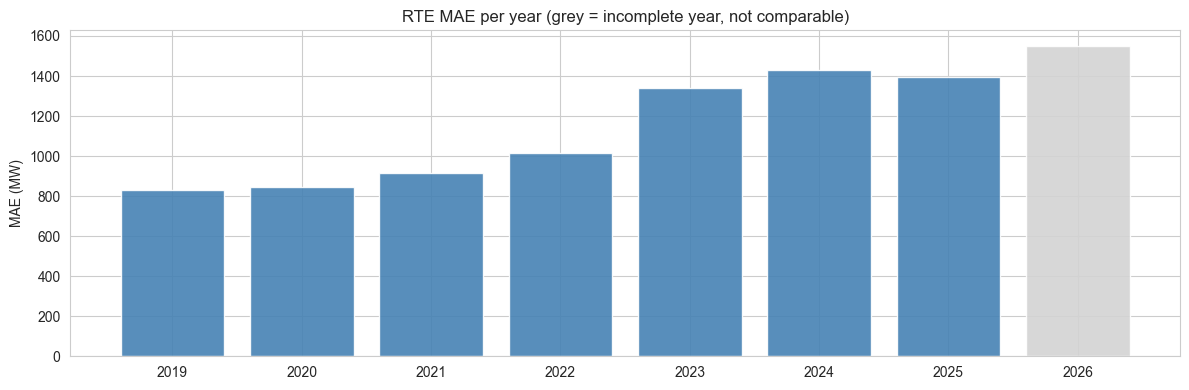

Complete years only: MAE 831 MW in 2019 -> 1397 MW in 2025 (1.7x).
=> Reporting a single full-sample MAE would flatter any model trained on recent data.
=> Our honest benchmark is RTE MAE measured on the SAME test period as our models.


In [22]:
# Is the benchmark stable over time? (decides how we build the test split)
yearly = df_rte.groupby('year').agg(
    mae=('abs_error', 'mean'),
    mape=('pct_error', 'mean'),
    bias=('error', 'mean'),
    hours=('error', 'size'),
)
yearly['complete'] = yearly.index.isin(COMPLETE_YEARS)
print('RTE performance per year:')
print(yearly.round(1))

fig, ax = plt.subplots(figsize=(12, 4))
colors = ['steelblue' if c else 'lightgrey' for c in yearly['complete']]
ax.bar(yearly.index.astype(str), yearly['mae'], alpha=0.9, color=colors)
ax.set_title('RTE MAE per year (grey = incomplete year, not comparable)')
ax.set_ylabel('MAE (MW)')
plt.tight_layout()
plt.show()

# Error is seasonal, so a Jan-Jun year is winter-weighted and not comparable to a full one.
full = yearly[yearly['complete']]
mae_first_year, mae_last_year = full['mae'].iloc[0], full['mae'].iloc[-1]
first_year, last_year = int(full.index[0]), int(full.index[-1])
drift = mae_last_year / mae_first_year
print(f'Complete years only: MAE {mae_first_year:.0f} MW in {first_year} '
      f'-> {mae_last_year:.0f} MW in {last_year} ({drift:.1f}x).')
print('=> Reporting a single full-sample MAE would flatter any model trained on recent data.')
print('=> Our honest benchmark is RTE MAE measured on the SAME test period as our models.')

In [23]:
# When does RTE fail? Error conditional on temperature and on load level
df_rte['temp_bucket'] = pd.cut(df_rte['temperature_c'], bins=TEMP_BINS)
print('MAE by temperature bucket:')
print(df_rte.groupby('temp_bucket', observed=False)['abs_error'].agg(['count', 'mean']).round(0))

print()
load_deciles = pd.qcut(df_rte['load_mw'], 10, labels=False)
print('MAE by load decile (0 = lowest load, 9 = highest):')
print(df_rte.groupby(load_deciles)['abs_error'].mean().round(0))

print()
EVENING_HOURS = range(18, 22)  # local evening peak
evening_winter = df_rte[df_rte['hour'].isin(EVENING_HOURS) & df_rte['month'].isin([12, 1, 2])]
print(f'Winter evening peaks ({EVENING_HOURS.start}-{EVENING_HOURS.stop - 1}h local, DJF): '
      f'{len(evening_winter)} hours')
print(f"MAE there: {evening_winter['abs_error'].mean():.0f} MW vs {rte_mae:.0f} MW overall")

MAE by temperature bucket:
              count    mean
temp_bucket                
(-inf, 0.0]    1016  1534.0
(0.0, 5.0]     7271  1279.0
(5.0, 10.0]   15738  1178.0
(10.0, 15.0]  16544  1217.0
(15.0, 20.0]  13815  1013.0
(20.0, 25.0]   7824   966.0
(25.0, inf]    3495  1083.0

MAE by load decile (0 = lowest load, 9 = highest):
load_mw
0     742.0
1     986.0
2    1083.0
3    1121.0
4    1126.0
5    1171.0
6    1214.0
7    1310.0
8    1318.0
9    1325.0
Name: abs_error, dtype: float64

Winter evening peaks (18-21h local, DJF): 2764 hours
MAE there: 1604 MW vs 1140 MW overall


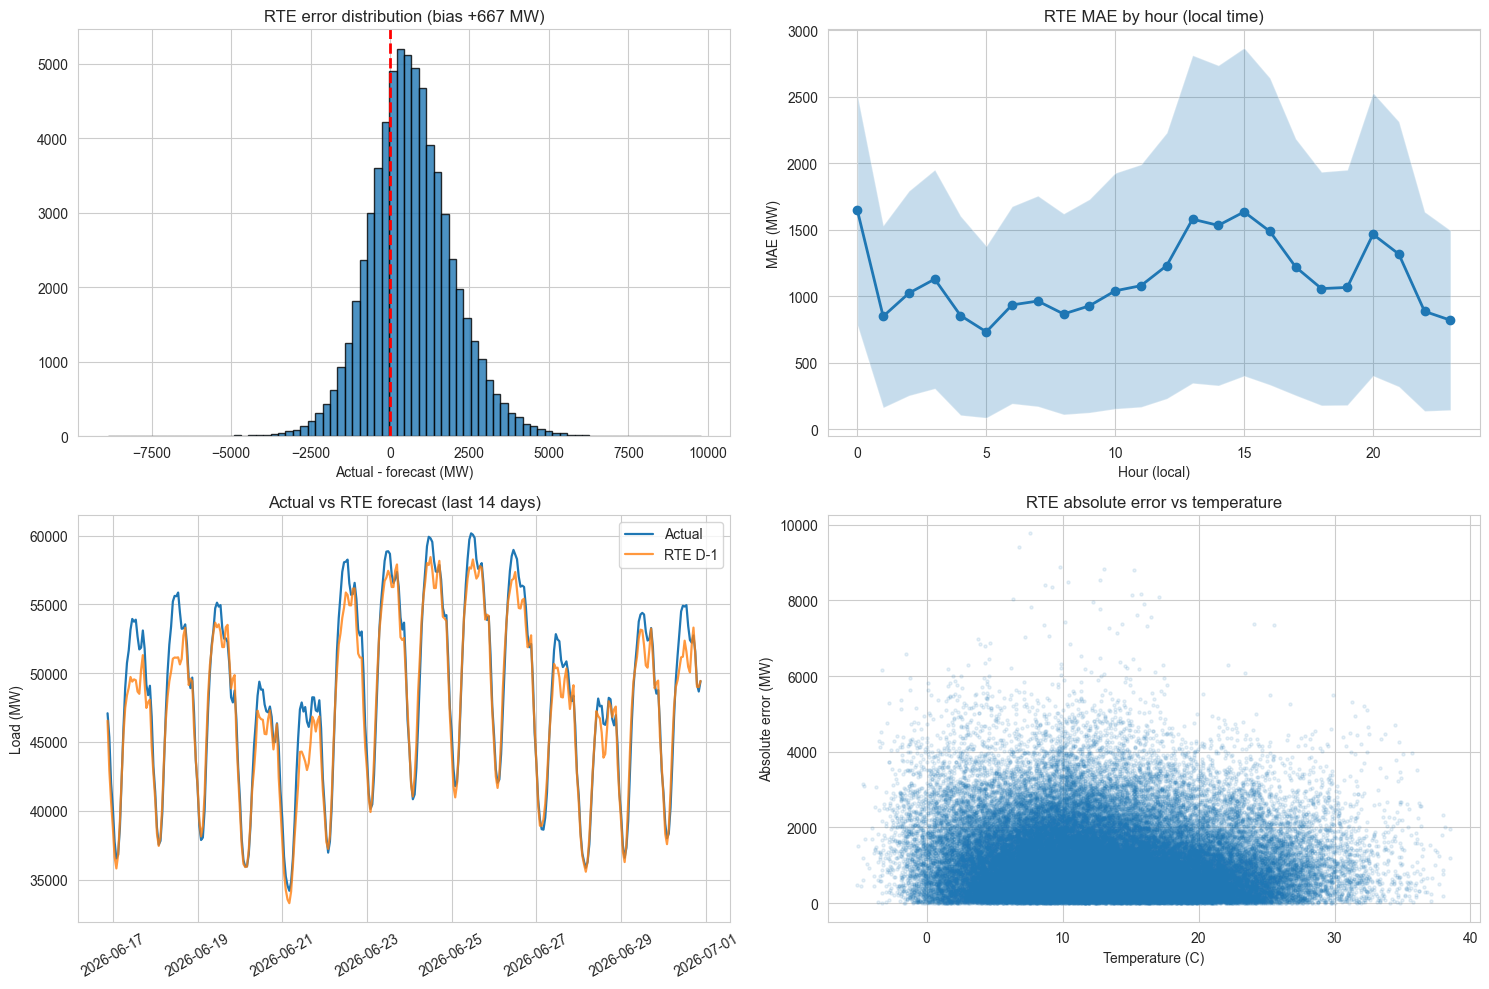

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes[0, 0].hist(df_rte['error'], bins=80, alpha=0.8, edgecolor='black')
axes[0, 0].axvline(0, color='r', linestyle='--', linewidth=2)
axes[0, 0].set_title(f'RTE error distribution (bias {rte_bias:+.0f} MW)')
axes[0, 0].set_xlabel('Actual - forecast (MW)')

axes[0, 1].plot(error_by_hour.index, error_by_hour['mean'], marker='o', linewidth=2)
axes[0, 1].fill_between(error_by_hour.index,
                        error_by_hour['mean'] - error_by_hour['std'],
                        error_by_hour['mean'] + error_by_hour['std'], alpha=0.25)
axes[0, 1].set_title('RTE MAE by hour (local time)')
axes[0, 1].set_xlabel('Hour (local)')
axes[0, 1].set_ylabel('MAE (MW)')

mask_14d = df_rte['datetime_utc'] >= df_rte['datetime_utc'].max() - pd.Timedelta(days=14)
axes[1, 0].plot(df_rte.loc[mask_14d, 'datetime_utc'], df_rte.loc[mask_14d, 'load_mw'],
                label='Actual', linewidth=1.6)
axes[1, 0].plot(df_rte.loc[mask_14d, 'datetime_utc'], df_rte.loc[mask_14d, 'rte_forecast_d1_mw'],
                label='RTE D-1', linewidth=1.6, alpha=0.8)
axes[1, 0].set_title('Actual vs RTE forecast (last 14 days)')
axes[1, 0].set_ylabel('Load (MW)')
axes[1, 0].tick_params(axis='x', rotation=30)
axes[1, 0].legend()

axes[1, 1].scatter(df_rte['temperature_c'], df_rte['abs_error'], alpha=0.1, s=5)
axes[1, 1].set_title('RTE absolute error vs temperature')
axes[1, 1].set_xlabel('Temperature (C)')
axes[1, 1].set_ylabel('Absolute error (MW)')

plt.tight_layout()
plt.show()

## 8. Key takeaways for modelling

In [25]:
# Every figure below is interpolated from the analysis above - no hardcoded numbers,
# so the summary cannot go stale on a data refresh.
peak_load = hourly_stats['mean'].max()
trough_load = hourly_stats['mean'].min()
intraday_spread = peak_load - trough_load
weekend_gap_pct = (weekday_mean - weekend_mean) / weekend_mean * 100
season_ratio = winter_mean / summer_mean
winter_peak_hour = int(profile['Winter'].idxmax())
summer_peak_hour = int(profile['Summer'].idxmax())
worst_hour = int(error_by_hour['mean'].idxmax())
worst_hour_mae = error_by_hour['mean'].max()
best_hour = int(error_by_hour['mean'].idxmin())
best_hour_mae = error_by_hour['mean'].min()
winter_evening_mae = evening_winter['abs_error'].mean()
p95_error = df_rte['abs_error'].quantile(0.95)
bias_direction = 'under-forecasts' if rte_bias > 0 else 'over-forecasts'
n_missing = len(nan_rows)
jan_outliers = int(outlier_months.get(1, 0))
regional_start = df_regional['datetime_utc'].min().date()
regional_share = df_regional['datetime_utc'].nunique() / len(df) * 100
regional_corr = comparison['load_mw'].corr(comparison['total_regional_load'])
hdd_corr = df_temp['hdd'].corr(df_temp['load_mw'])

summary = f"""
KEY TAKEAWAYS FOR MODELLING

All clock-based figures are in Europe/Paris local time, because consumption follows the local
clock. Deriving hour-of-day from UTC would mix two different local hours across DST switches.

1. Intra-day shape dominates, and it moves with the season
   Overall peak {peak_hour}h ({peak_load:.0f} MW) vs trough {trough_hour}h ({trough_load:.0f} MW),
   spread {intraday_spread:.0f} MW. The winter peak sits at {winter_peak_hour}h while the summer peak
   sits at {summer_peak_hour}h: hour-of-day must interact with season, not stand alone.

2. Calendar effects are large
   Weekday vs weekend gap: {weekday_mean - weekend_mean:.0f} MW ({weekend_gap_pct:.1f}%).
   Day-of-week plus public-holiday flags are mandatory features.

3. Seasonality is thermal, not a month dummy
   Winter/summer ratio {season_ratio:.2f}x. Correlation(temp, load) = {temp_corr:.3f}, but
   correlation(HDD, load) = {hdd_corr:.3f}: the relationship is U-shaped and the heating side
   carries the signal. Thermal gradient below {BASE_TEMP:.0f}C is about {abs(slope):.0f} MW per degree lost.
   Use HDD/CDD and a quadratic term rather than raw temperature.

4. The recent past is extremely informative
   Autocorrelation {autocorr[1]:.2f} at 1h, {autocorr[24]:.2f} at 24h, {autocorr[168]:.2f} at 168h.
   This justifies both SARIMA seasonal terms (s=24) and lag features at 1h / 24h / 168h.
   Caveat: at D-1 noon we do NOT know lag 1h for most of D+1, so lags must be built only from
   information available before the auction closes. This is the main leakage trap.

5. RTE is strong but beatable - and it is drifting
   Full sample: MAE {rte_mae:.0f} MW, RMSE {rte_rmse:.0f} MW, MAPE {rte_mape:.2f}%,
   bias {rte_bias:+.0f} MW (RTE systematically {bias_direction}).
   On complete years only, MAE went from {mae_first_year:.0f} MW in {first_year} to
   {mae_last_year:.0f} MW in {last_year} ({drift:.1f}x).
   => Never quote the full-sample number as the benchmark; quote RTE on our own test window.

6. The expensive hours are the weak hours
   Worst hour {worst_hour}h ({worst_hour_mae:.0f} MW) vs best hour {best_hour}h ({best_hour_mae:.0f} MW).
   Winter evening peaks ({EVENING_HOURS.start}-{EVENING_HOURS.stop - 1}h, DJF): {winter_evening_mae:.0f} MW
   vs {rte_mae:.0f} MW overall, and MAE rises monotonically with the load decile.
   P95 absolute error = {p95_error:.0f} MW sets the scale of the band we owe the desk.

7. Data quality is good, with two things to handle explicitly
   {n_missing} missing load values, all at the October DST fall-back hour - interpolate and flag
   DST days. The {n_outliers} IQR outliers are mostly January ({jan_outliers} of them): genuine
   cold-snap peaks, so they must be kept, not clipped.

8. Regional file is a feature source, not a second target
   It reconciles with the national series (correlation {regional_corr:.4f}), but it only starts
   {regional_start} and covers {regional_share:.0f}% of the national history. Using regional features
   would cut the training set from 7.5 years to about 3.5. Treat it as an optional enrichment
   to test late, once the national pipeline is validated.
"""

print(summary)


KEY TAKEAWAYS FOR MODELLING

All clock-based figures are in Europe/Paris local time, because consumption follows the local
clock. Deriving hour-of-day from UTC would mix two different local hours across DST switches.

1. Intra-day shape dominates, and it moves with the season
   Overall peak 12h (56863 MW) vs trough 4h (43258 MW),
   spread 13605 MW. The winter peak sits at 19h while the summer peak
   sits at 13h: hour-of-day must interact with season, not stand alone.

2. Calendar effects are large
   Weekday vs weekend gap: 5423 MW (11.4%).
   Day-of-week plus public-holiday flags are mandatory features.

3. Seasonality is thermal, not a month dummy
   Winter/summer ratio 1.48x. Correlation(temp, load) = -0.605, but
   correlation(HDD, load) = 0.716: the relationship is U-shaped and the heating side
   carries the signal. Thermal gradient below 15C is about 1797 MW per degree lost.
   Use HDD/CDD and a quadratic term rather than raw temperature.

4. The recent past is extremely inf